# Level 1, Task 2: Data Cleaning and Preprocessing
**Codveda Technology | Data Science Internship**

**Prepared by | Suleiman Habeebulahi**

**Sumary of Tasks done :**

In this notebook I cleaned and prepared the telecom customer churn data (`churn-bigml-80.csv`) so it is ready for analysis and modelling. I checked for missing values and duplicates, deal with outliers, converted the text columns to numbers and scale the numeric columns. At the end I saved two files: a readable cleaned copy (used for the EDA in Task 3) and a fully numeric, scaled copy (for modelling).

## 1.0 Setting Up

### 1.1 Importing the Libraries

In [1]:
import pandas as pd                 # load and work with the data tables
import numpy as np                  # numeric helpers (masks for the heatmap)
import matplotlib.pyplot as plt      # base plotting
import seaborn as sns                # box plots, histograms and heatmap
from sklearn.preprocessing import StandardScaler   # scale the numeric columns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

**Result:** The libraries loaded without any error. I will use pandas for the tables, matplotlib and seaborn for the charts, and scikit-learn for scaling.

### 1.2 Loading the Dataset

In [2]:
DATA_PATH = "churn-bigml-80.csv"

df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


**Interpretation:** The dataset has 2,666 customers (rows) and 20 columns. Each row is one customer, with their plan type, call minutes, call counts, charges, number of customer service calls, and whether they left (Churn). The column names still have capital letters and spaces, which I fix in section 2.1.

### 1.3 Checking Column Types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

**Interpretation:** There are no empty cells reported here (every column shows 2,666 non-null values). Most columns are already numbers. State, International plan and Voice mail plan are text, and Churn is True/False. Area code is stored as a number, which I will correct later because it is really a label.

## 2.0 Basic Data Cleaning

### 2.1 Standardising the Column Names

In [4]:
# lower casing and underscoring, to standardize all column names into same format
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
list(df.columns)

['state',
 'account_length',
 'area_code',
 'international_plan',
 'voice_mail_plan',
 'number_vmail_messages',
 'total_day_minutes',
 'total_day_calls',
 'total_day_charge',
 'total_eve_minutes',
 'total_eve_calls',
 'total_eve_charge',
 'total_night_minutes',
 'total_night_calls',
 'total_night_charge',
 'total_intl_minutes',
 'total_intl_calls',
 'total_intl_charge',
 'customer_service_calls',
 'churn']

**Interpretation:** The column names are now in lower case with underscores, for example `total_day_minutes`. This makes them easier to type and avoids mistakes with spaces.

### 2.2 Handling Missing Values

In [5]:
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0])

# fallback in case anything is missing: median for numbers, most common value for the rest
num_cols = df.select_dtypes(include="number").columns
other_cols = df.select_dtypes(exclude="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in other_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after imputation:", df.isnull().sum().sum())

Total missing values: 0
Series([], dtype: int64)
Missing values after imputation: 0


**Interpretation:** There are no missing values in this dataset, so no row or column needed to be dropped or filled. I still kept the imputation code (median for numbers, most common value for text) so the same steps would work on a dataset that does have gaps. The count after imputation is still 0, which confirms nothing was changed.

### 2.3 Removing Duplicate Rows

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 0
Rows left: 2666


**Interpretation:** There are no duplicate rows, so all 2,666 rows stay. This means no customer is counted twice.

### 2.4 Fixing Data Types and Checking for Invalid Values

In [7]:
df["churn"] = df["churn"].astype(int)           # True/False to 1/0
df["area_code"] = df["area_code"].astype(str)   # it is a label, not a quantity

numeric_only = df.select_dtypes(include="number")
print("Negative values found:", (numeric_only < 0).sum().sum())
df[["churn", "area_code"]].dtypes

Negative values found: 0


churn        int64
area_code      str
dtype: object

**Interpretation:** `churn` is now 1 (left) and 0 (stayed), which lets me calculate a churn rate by taking the average. `area_code` is now text, because 408, 415 and 510 only name regions and 510 is not 'more' than 408. There are no negative values, so there are no obvious data entry errors in minutes, calls or charges.

## 3.0 Outlier Detection and Removal

### 3.1 Looking at the Outliers with Box Plots

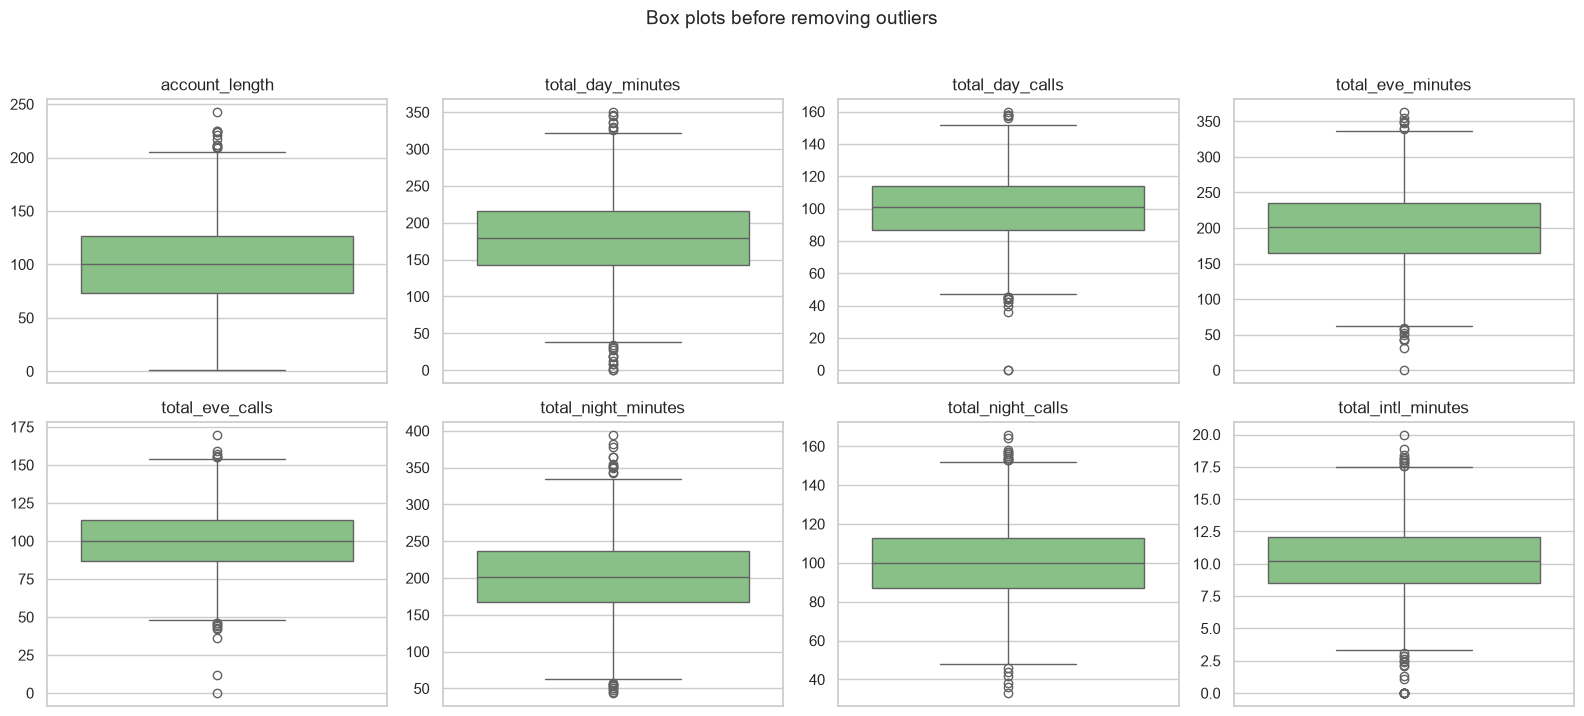

In [8]:
# columns I will test. I left out the charge columns (they just mirror minutes),
# customer_service_calls (high values are real signal), and the two count columns
# with many zeros (number_vmail_messages, total_intl_calls)
outlier_cols = ["account_length",
                "total_day_minutes", "total_day_calls",
                "total_eve_minutes", "total_eve_calls",
                "total_night_minutes", "total_night_calls",
                "total_intl_minutes"]

def plot_boxes(data, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, col in zip(axes.ravel(), outlier_cols):
        sns.boxplot(y=data[col], ax=ax, color="#7fc97f")
        ax.set_title(col)
        ax.set_ylabel("")
    plt.suptitle(title, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_boxes(df, "Box plots before removing outliers")

**Interpretation:** Most columns have a few dots beyond the whiskers, which are the unusual values. The `total_intl_minutes` column has the most. The middle of each box looks fairly balanced, so the data is not badly skewed. I only test the eight usage columns. I left out the charge columns because charge is minutes multiplied by a fixed rate, so it would flag the same customers twice. I also left out `customer_service_calls`, because customers with many calls are the ones most likely to leave and I want to keep them.

### 3.2 Detecting Outliers with the IQR Rule

In [9]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

flags = pd.DataFrame(index=df.index)
limits = {}
for col in outlier_cols:
    low, high = iqr_bounds(df[col])
    limits[col] = (round(low, 1), round(high, 1))
    flags[col] = (df[col] < low) | (df[col] > high)

print("Outliers per column:")
print(flags.sum())
pd.DataFrame(limits, index=["lower_limit", "upper_limit"]).T

Outliers per column:
account_length         12
total_day_minutes      21
total_day_calls        18
total_eve_minutes      17
total_eve_calls        15
total_night_minutes    22
total_night_calls      19
total_intl_minutes     37
dtype: int64


,lower_limit,upper_limit
account_length,-8.0,208.0
total_day_minutes,34.7,324.6
total_day_calls,46.5,154.5
total_eve_minutes,60.6,339.8
total_eve_calls,46.5,154.5
total_night_minutes,62.6,340.8
total_night_calls,48.0,152.0
total_intl_minutes,3.1,17.5


**Interpretation:** The IQR rule flags between 12 and 37 customers per column, and `total_intl_minutes` has the most (37). The table shows the limits used. For example, a customer with more than about 325 day minutes, or fewer than about 35, is treated as an outlier. I chose IQR over the mean plus or minus 3 standard deviations because it depends on percentiles, so the extreme values do not distort the limits.

### 3.3 Removing the Outliers

Rows before: 2666, removed: 154, left: 2512
Share removed: 5.8%
Churn rate before: 14.6%, after: 14.3%


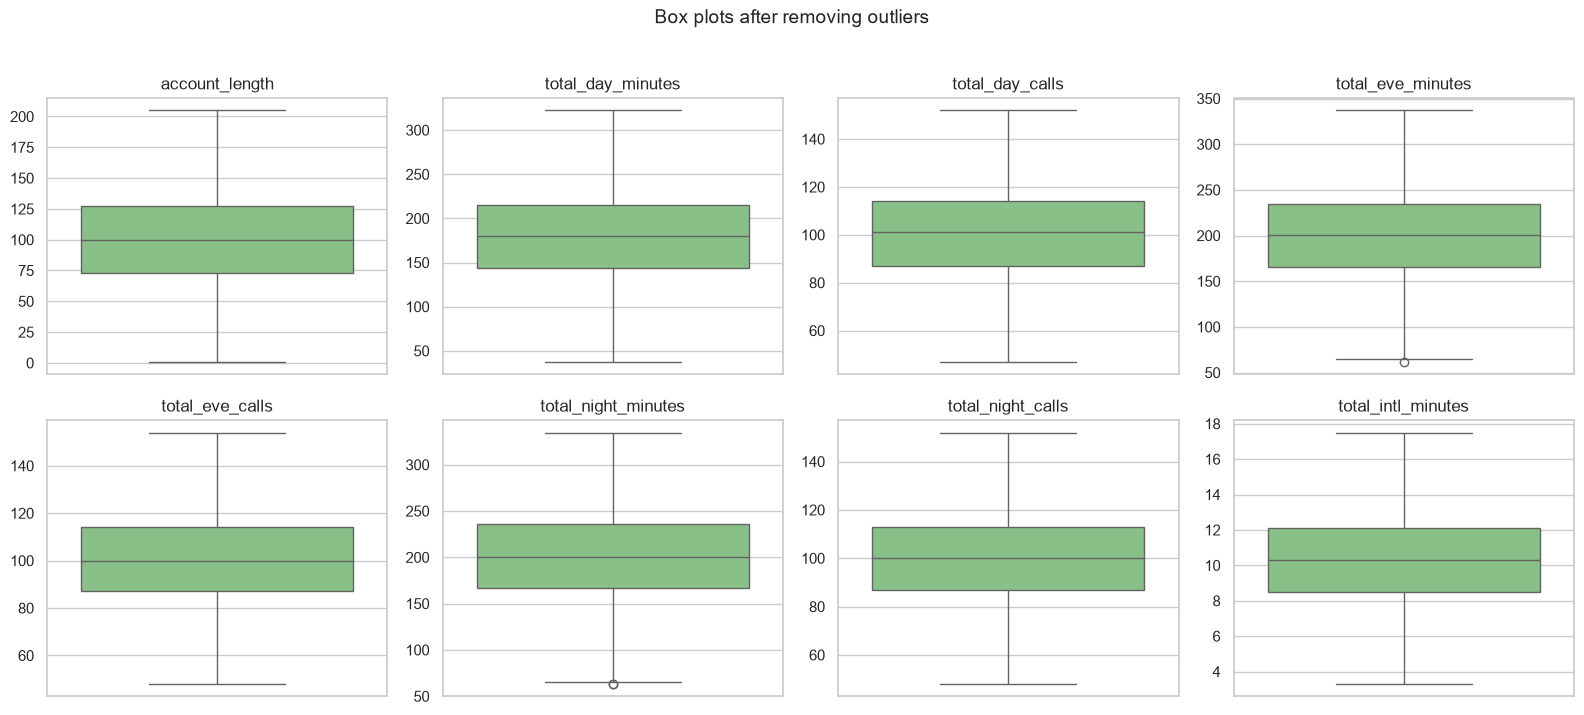

In [10]:
rows_to_drop = flags.any(axis=1)      # a row goes if any tested column is an outlier
rows_before = len(df)
churn_before = df["churn"].mean()

df = df[~rows_to_drop].reset_index(drop=True)

print(f"Rows before: {rows_before}, removed: {rows_to_drop.sum()}, left: {len(df)}")
print(f"Share removed: {rows_to_drop.mean():.1%}")
print(f"Churn rate before: {churn_before:.1%}, after: {df['churn'].mean():.1%}")

plot_boxes(df, "Box plots after removing outliers")

**Interpretation:** I removed 154 customers, which is 5.8% of the data (some customers were flagged in more than one column). The churn rate moved only from 14.6% to 14.3%, so the removal did not change the target I want to predict later. In the box plots after removal, the extreme dots are mostly gone. One or two points remain just outside the whiskers because the quartiles shifted slightly. I stopped after one pass, because repeating it would keep trimming normal customers.

## 4.0 Encoding Categorical Variables

### 4.1 Label Encoding the Plan Columns

In [11]:
df["international_plan"] = df["international_plan"].map({"No": 0, "Yes": 1})
df["voice_mail_plan"] = df["voice_mail_plan"].map({"No": 0, "Yes": 1})

# every value should have been mapped, otherwise something was spelt differently
assert df[["international_plan", "voice_mail_plan"]].notnull().all().all()

df_clean = df.copy()    # readable version, I kept for the EDA notebook

print(df_clean["international_plan"].value_counts())
print(df_clean["voice_mail_plan"].value_counts())

international_plan
0    2260
1     252
Name: count, dtype: int64
voice_mail_plan
0    1813
1     699
Name: count, dtype: int64


**Interpretation:** The two plan columns are now 0 and 1. Only 252 customers (about 10%) have an international plan, and 699 (about 28%) have a voice mail plan. I used label encoding here because each column has only two values, so one 0/1 column keeps all the information. The assert line passed, which means every value was mapped correctly. I also saved this readable version as `df_clean` for the EDA.

### 4.2 One-Hot Encoding State and Area Code

In [12]:
df_encoded = pd.get_dummies(df_clean, columns=["state", "area_code"],
                            drop_first=True, dtype=int)

print("Columns before:", df_clean.shape[1])
print("Columns after :", df_encoded.shape[1])
df_encoded[["state_AL", "state_TX", "area_code_415", "area_code_510"]].head()

Columns before: 20
Columns after : 70


,state_AL,state_TX,area_code_415,area_code_510
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,0,0
4,0,0,1,0


**Interpretation:** The number of columns went from 20 to 70. That is 50 new state columns (51 states with one dropped) and 2 area code columns. I used one-hot encoding for state and area code because they have no natural order, and label numbers like AK=0, AL=1 would wrongly suggest one state is bigger than another. I dropped one category in each group (`drop_first=True`) because it can be worked out from the others, and keeping it would repeat information. The sample shows customers 0 to 2 and 4 are in area code 415, and customer 3 is in the dropped area code (408).

## 5.0 Scaling the Numerical Features

### 5.1 Standardising the Continuous Columns

In [13]:
# the 0/1 columns and the target stay as they are
skip = ["international_plan", "voice_mail_plan", "churn"]
scale_cols = [c for c in df_clean.select_dtypes(include="number").columns if c not in skip]

scaler = StandardScaler()
df_final = df_encoded.copy()
df_final[scale_cols] = scaler.fit_transform(df_final[scale_cols])

print("Columns scaled:", len(scale_cols))
print(scale_cols)

Columns scaled: 15
['account_length', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes', 'total_eve_calls', 'total_eve_charge', 'total_night_minutes', 'total_night_calls', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'customer_service_calls']


**Interpretation:** I scaled 15 continuous columns. I did not scale the 0/1 columns or `churn`, because they are already on a 0 to 1 scale and `churn` is the value I want to predict, not an input. I used standardisation because the columns are on very different scales (for example account length is around 100 while day charge is around 30), and models like logistic regression, SVM and K-Means would otherwise give more weight to the bigger numbers.

### 5.2 Checking the Result of Scaling

In [14]:
before = df_clean[scale_cols].agg(["mean", "std"]).T.round(2)
after = df_final[scale_cols].agg(["mean", "std"]).T.round(2)
pd.concat([before, after], axis=1, keys=["before scaling", "after scaling"]).head(8)

before scaling        after scaling     
                                mean    std          mean  std
account_length                100.16  38.80           0.0  1.0
number_vmail_messages           8.14  13.70           0.0  1.0
total_day_minutes             179.79  52.43           0.0  1.0
total_day_calls               100.48  19.28           0.0  1.0
total_day_charge               30.56   8.91           0.0  1.0
total_eve_minutes             200.54  49.45           0.0  1.0
total_eve_calls               100.10  19.61          -0.0  1.0
total_eve_charge               17.05   4.20          -0.0  1.0

**Interpretation:** After scaling, every column has a mean of 0 and a standard deviation of 1, so the scaling worked. For example, `account_length` had a mean of about 100 and a standard deviation of about 39 before scaling. A few means show -0.0, which is just rounding of a very small number.

## 6.0 Saving the Cleaned Data

### 6.1 Exporting the Files

In [15]:
df_clean.to_csv("churn_cleaned.csv", index=False)
df_final.to_csv("churn_preprocessed_scaled.csv", index=False)

print("churn_cleaned.csv:", df_clean.shape)
print("churn_preprocessed_scaled.csv:", df_final.shape)

churn_cleaned.csv: (2512, 20)
churn_preprocessed_scaled.csv: (2512, 70)


**Interpretation:** I saved two files. `churn_cleaned.csv` has 2,512 rows and 20 columns and stays readable, so I used it for the EDA. `churn_preprocessed_scaled.csv` has 2,512 rows and 70 columns, fully numeric and scaled, so it is ready for modelling.

## 7.0 Summary

| Step | What I did | Result |
|---|---|---|
| Column names standardization | Lower case with underscores | Consistent names |
| Missing values handling| Checked, with median/mode fallback | None found |
| Duplicates handling | Checked and dropped | None found |
| Data types validation | `churn` to 1/0, `area_code` to text | Correct meaning for each column |
| Outliers detection and handling | IQR rule on 8 usage columns | 154 rows (5.8%) removed, churn rate 14.6% to 14.3% |
| Encoding | Label (2 plan columns), one-hot (state, area code) | All columns numeric, 70 columns |
| Scaling | StandardScaler on 15 continuous columns | Mean 0, standard deviation 1 |

The data is now clean: 2,512 customers, no gaps, no duplicates, and no extreme usage values. The main thing to remember for later is that only about 14% of customers churn, so the classes are imbalanced.